In [1]:
import glob
from pathlib import Path

import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
from matplotlib.gridspec import GridSpec

from shared.paths import load_paths
paths = load_paths()

# ------------------------------------------------------------
# Fig. 3 inputs
# ------------------------------------------------------------
TS_ROOT = Path(paths.cp4_2d) / "CP4_box_JASMIN/mean3h_v2/timeseries"
MODEL_ROOT = Path(paths.cp4_2d) / "CP4_box_JASMIN/SM_model_comparison25"

MONTH = 8
HOURS = [17, 18, 19]
DAYS = 30
BOX_PIXELS = 23
RAIN_T0_MIN = 1.0

SM_CLIM = {
    "hist": 14.351013728114538,
    "future": 11.584353943636033,
}


HIST_COL = "#3fa3a0"
FUT_COL  = "#9a5f8f"  

COL = {"hist": HIST_COL, "future": FUT_COL}
LS = {"hist": "-", "future": "-"}

var_info = {
    "lsRain": {"label": "Rainfall", "unit": r"mm h$^{-1}$"},
    "sh": {"label": "Sensible heat flux", "unit": r"W m$^{-2}$"},
    "SM": {"label": "Soil moisture", "unit": r"kg m$^{-2}$"},
}

plt.rcParams.update({
    "font.size": 9.5,
    "axes.titlesize": 11,
    "axes.titleweight": "normal",
    "axes.labelsize": 9.5,
    "axes.linewidth": 1.0,
})

In [2]:
# ============================================================
# PANEL (a): storm-centred time series
# Build once from *_timeseries.nc, then use cached summary
# ============================================================

FIG3_CACHE = TS_ROOT / "fig3_intermediates"
FIG3_CACHE.mkdir(parents=True, exist_ok=True)

hours_tag = "".join(str(h) for h in HOURS)
rain_tag = str(RAIN_T0_MIN).replace(".", "p")

TS_SUMMARY_FILE = FIG3_CACHE / (
    f"Fig3_timeseries_Aug{MONTH:02d}_h{hours_tag}_"
    f"pm{DAYS}d_box{BOX_PIXELS}px_rainT0gt{rain_tag}.csv"
)

FORCE_REBUILD_TS = False   # set True if you deliberately want to recalculate


def timeseries_files(label, hour):
    ftag = "hist" if label == "hist" else "fut"
    folder = TS_ROOT / (
        f"SM_sh_lsRain_Aug{MONTH:02d}_{ftag}_{hour:02d}UTC_"
        f"pm{DAYS}d_box{BOX_PIXELS:02d}px"
    )
    return sorted(folder.glob("*_timeseries.nc"))


def get_var_lag(ds, var):
    da = ds[var]
    lag_name = f"lag_hour_{var}"

    lag = (
        da.coords[lag_name].values
        if lag_name in da.coords
        else ds[lag_name].values
    )

    return np.asarray(lag, float).squeeze(), np.asarray(da.values, float).squeeze()


def onto_reference(lag, vals, ref):
    """Put a series onto the reference lag grid if necessary."""
    if len(lag) == len(ref) and np.allclose(lag, ref, atol=1e-5):
        return vals

    ok = np.isfinite(lag) & np.isfinite(vals)

    if ok.sum() < 2:
        return np.full(len(ref), np.nan)

    return np.interp(
        ref, lag[ok], vals[ok],
        left=np.nan, right=np.nan
    )


def build_timeseries_summary(lag_min=-240, lag_max=240):
    """
    Read every storm file once.

    Keep only storms with lsRain(t=0) > RAIN_T0_MIN and directly
    accumulate mean, standard deviation, SEM and 95% CI.
    """
    acc = {}
    accepted = {"hist": 0, "future": 0}

    for label in ["hist", "future"]:
        for hour in HOURS:

            files = timeseries_files(label, hour)
            print(f"{label:6s} {hour:02d} UTC: {len(files)} files")

            for n, path in enumerate(files):

                if n % 1000 == 0 and n > 0:
                    print(f"    {n}/{len(files)}")

                try:
                    with xr.open_dataset(path) as ds:

                        # ------------------------------------------------
                        # Same sample filter used in the analysis:
                        # rain at storm time must exceed 1 mm h-1
                        # ------------------------------------------------
                        rlag, rain = get_var_lag(ds, "lsRain")

                        if len(rlag) == 0:
                            continue

                        i0 = int(np.nanargmin(np.abs(rlag)))

                        if abs(rlag[i0]) > 0.75:
                            continue

                        if (
                            not np.isfinite(rain[i0]) or
                            rain[i0] <= RAIN_T0_MIN
                        ):
                            continue

                        accepted[label] += 1

                        # ------------------------------------------------
                        # Accumulate the three Fig. 3(a) variables
                        # ------------------------------------------------
                        for var in ["lsRain", "sh", "SM"]:

                            lag, vals = get_var_lag(ds, var)

                            keep = (
                                (lag >= lag_min) &
                                (lag <= lag_max)
                            )

                            lag = lag[keep]
                            vals = vals[keep]

                            key = (label, var)

                            if key not in acc:
                                acc[key] = {
                                    "lag": lag.copy(),
                                    "sum": np.zeros(len(lag), dtype=float),
                                    "sumsq": np.zeros(len(lag), dtype=float),
                                    "count": np.zeros(len(lag), dtype=int),
                                }

                            ref = acc[key]["lag"]
                            vals = onto_reference(lag, vals, ref)

                            good = np.isfinite(vals)

                            acc[key]["sum"][good] += vals[good]
                            acc[key]["sumsq"][good] += vals[good]**2
                            acc[key]["count"][good] += 1

                except Exception as exc:
                    print("FAILED:", path.name, exc)

    # --------------------------------------------------------
    # Convert running sums into statistics
    # --------------------------------------------------------
    rows = []

    for (label, var), a in acc.items():

        n = a["count"].astype(float)

        mean = np.divide(
            a["sum"], n,
            out=np.full_like(a["sum"], np.nan),
            where=n > 0,
        )

        variance = np.divide(
            a["sumsq"] - a["sum"]**2 / n,
            n - 1,
            out=np.full_like(a["sum"], np.nan),
            where=n > 1,
        )

        # Protect against tiny negative floating-point residuals
        variance = np.maximum(variance, 0)

        stdv = np.sqrt(variance)
        sem = stdv / np.sqrt(n)
        ci95 = 1.96 * sem

        rows.append(
            pd.DataFrame({
                "label": label,
                "var": var,
                "lag_hour": a["lag"],
                "mean": mean,
                "std": stdv,
                "sem": sem,
                "ci95": ci95,
                "count": n.astype(int),
            })
        )

    out = pd.concat(rows, ignore_index=True)

    print("\nAccepted storms:")
    print("  HIST  :", accepted["hist"])
    print("  FUTURE:", accepted["future"])

    return out


# ============================================================
# BUILD OR LOAD
# ============================================================

if TS_SUMMARY_FILE.exists() and not FORCE_REBUILD_TS:

    print("Reading cached Fig. 3 time-series summary:")
    print(TS_SUMMARY_FILE)

    ts_summary = pd.read_csv(TS_SUMMARY_FILE)

else:

    print("No cached summary found — building from *_timeseries.nc files...")

    ts_summary = build_timeseries_summary(
        lag_min=-240,
        lag_max=240,
    )

    ts_summary.to_csv(TS_SUMMARY_FILE, index=False)

    print("\nSaved:")
    print(TS_SUMMARY_FILE)


display(ts_summary.head())

print("\nSample counts:")
display(
    ts_summary.groupby(["label", "var"])["count"]
              .max()
              .rename("N storms")
)

Reading cached Fig. 3 time-series summary:
/gws/ssde/j25b/lmcs/cklein/CP_models/MCS_files/WAf/CP4_box_JASMIN/mean3h_v2/timeseries/fig3_intermediates/Fig3_timeseries_Aug08_h171819_pm30d_box23px_rainT0gt1p0.csv


,label,var,lag_hour,mean,std,sem,ci95,count
0,hist,lsRain,-239.5,0.409535,0.957701,0.010903,0.021369,7716
1,hist,lsRain,-238.5,0.388581,1.004042,0.011430,0.022403,7716
2,hist,lsRain,-237.5,0.371749,1.048182,0.011933,0.023388,7716
3,hist,lsRain,-236.5,0.358059,1.085061,0.012353,0.024211,7716
4,hist,lsRain,-235.5,0.341563,1.107655,0.012610,0.024715,7716



Sample counts:


label   var   
future  SM        6243
        lsRain    6243
        sh        6243
hist    SM        7716
        lsRain    7716
        sh        7716
Name: N storms, dtype: int64

In [3]:
# ============================================================
# Drydown detailed diagnostics
# ============================================================

detail_files = sorted(
    glob.glob(
        str(TS_ROOT / "all_wetting_drydown_events_*_detailed_diagnostics.csv")
    )
)

if not detail_files:
    raise FileNotFoundError("No *_detailed_diagnostics.csv found")

detail_file = detail_files[-1]
print("Drydown:", Path(detail_file).name)

ev = pd.read_csv(detail_file)

# Main Fig. 3 decomposition uses the hydrological event definition.
DEFINITION = "SM>=2.5"

dd = ev[
    (ev["definition"] == DEFINITION) &
    np.isfinite(ev["available_drying_days"]) &
    np.isfinite(ev["dSM_to_min"]) &
    (ev["available_drying_days"] > 0)
].copy()

# Conditional mean drydown as a function of available drying time.
duration_bins = np.arange(0.5, 15.5, 0.5)
dd["duration_bin"] = pd.cut(dd["available_drying_days"], duration_bins)

curve = (
    dd.groupby(["label", "duration_bin"], observed=True)
      .agg(
          days=("available_drying_days", "median"),
          drying=("dSM_to_min", "mean"),
          n=("dSM_to_min", "size"),
      )
      .reset_index()
)

curve = curve[curve["n"] >= 50].copy()


def drying_at_duration(label, days):
    s = curve[curve["label"] == label].sort_values("days")
    x = s["days"].values
    y = s["drying"].values

    if len(x) < 2 or days < x.min() or days > x.max():
        return np.nan

    return np.interp(days, x, y)


percentiles = [25, 50, 75, 90]
rows = []

for p in percentiles:
    TH = np.nanpercentile(
        dd.loc[dd["label"] == "hist", "available_drying_days"], p
    )
    TF = np.nanpercentile(
        dd.loc[dd["label"] == "future", "available_drying_days"], p
    )

    HH = drying_at_duration("hist", TH)
    HF = drying_at_duration("hist", TF)
    FH = drying_at_duration("future", TH)
    FF = drying_at_duration("future", TF)

    total = FF - HH

    # Symmetric duration/response decomposition
    duration = 0.5 * ((HF - HH) + (FF - FH))
    response = 0.5 * ((FF - HF) + (FH - HH))

    rows.append({
        "percentile": p,
        "T_hist": TH,
        "T_future": TF,
        "D_hist_at_Thist": HH,
        "D_hist_at_Tfuture": HF,
        "D_future_at_Thist": FH,
        "D_future_at_Tfuture": FF,
        "total_difference": total,
        "duration_contribution": duration,
        "response_contribution": response,
        "duration_percent": 100*duration/total if total != 0 else np.nan,
        "response_percent": 100*response/total if total != 0 else np.nan,
    })

decomp = pd.DataFrame(rows)

display(decomp.round(2))


# ============================================================
# Model-wide SM variability and wavelets
# ============================================================

std_file = MODEL_ROOT / "SM_temporal_std_JAS12_onP25.nc"
wav_file = MODEL_ROOT / "SM_wavelet_persistence_JAS12_onP25.nc"

print("STD:    ", std_file.name)
print("Wavelet:", wav_file.name)

std = xr.open_dataset(std_file)
wav = xr.open_dataset(wav_file)

Drydown: all_wetting_drydown_events_Aug08_hours171819_SMwet2p5_Rain5p0mm_Dry2p5_gap12h_pm30d_box23px_detailed_diagnostics.csv


,percentile,T_hist,T_future,D_hist_at_Thist,D_hist_at_Tfuture,D_future_at_Thist,D_future_at_Tfuture,total_difference,duration_contribution,response_contribution,duration_percent,response_percent
0,25,1.50,1.71,4.90,5.31,4.85,5.32,0.41,0.44,-0.02,105.35,-5.35
1,50,2.50,3.00,7.06,7.98,7.93,9.19,2.13,1.09,1.04,51.18,48.82
2,75,3.92,4.75,9.36,10.35,10.70,12.48,3.12,1.39,1.73,44.45,55.55
3,90,5.79,6.88,11.53,12.88,13.67,15.92,4.39,1.80,2.59,41.01,58.99


STD:     SM_temporal_std_JAS12_onP25.nc
Wavelet: SM_wavelet_persistence_JAS12_onP25.nc


Longer drying duration:       51.4%
Stronger fixed-time drying:   48.6%
Check:                        100.0%

Contribution by percentile:
P25: duration 105.4%, response -5.4%
P50: duration 51.2%, response 48.8%
P75: duration 44.4%, response 55.6%


/tmp/ipykernel_1130/299782397.py:372: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(w_pad=1.7, h_pad=2.0)


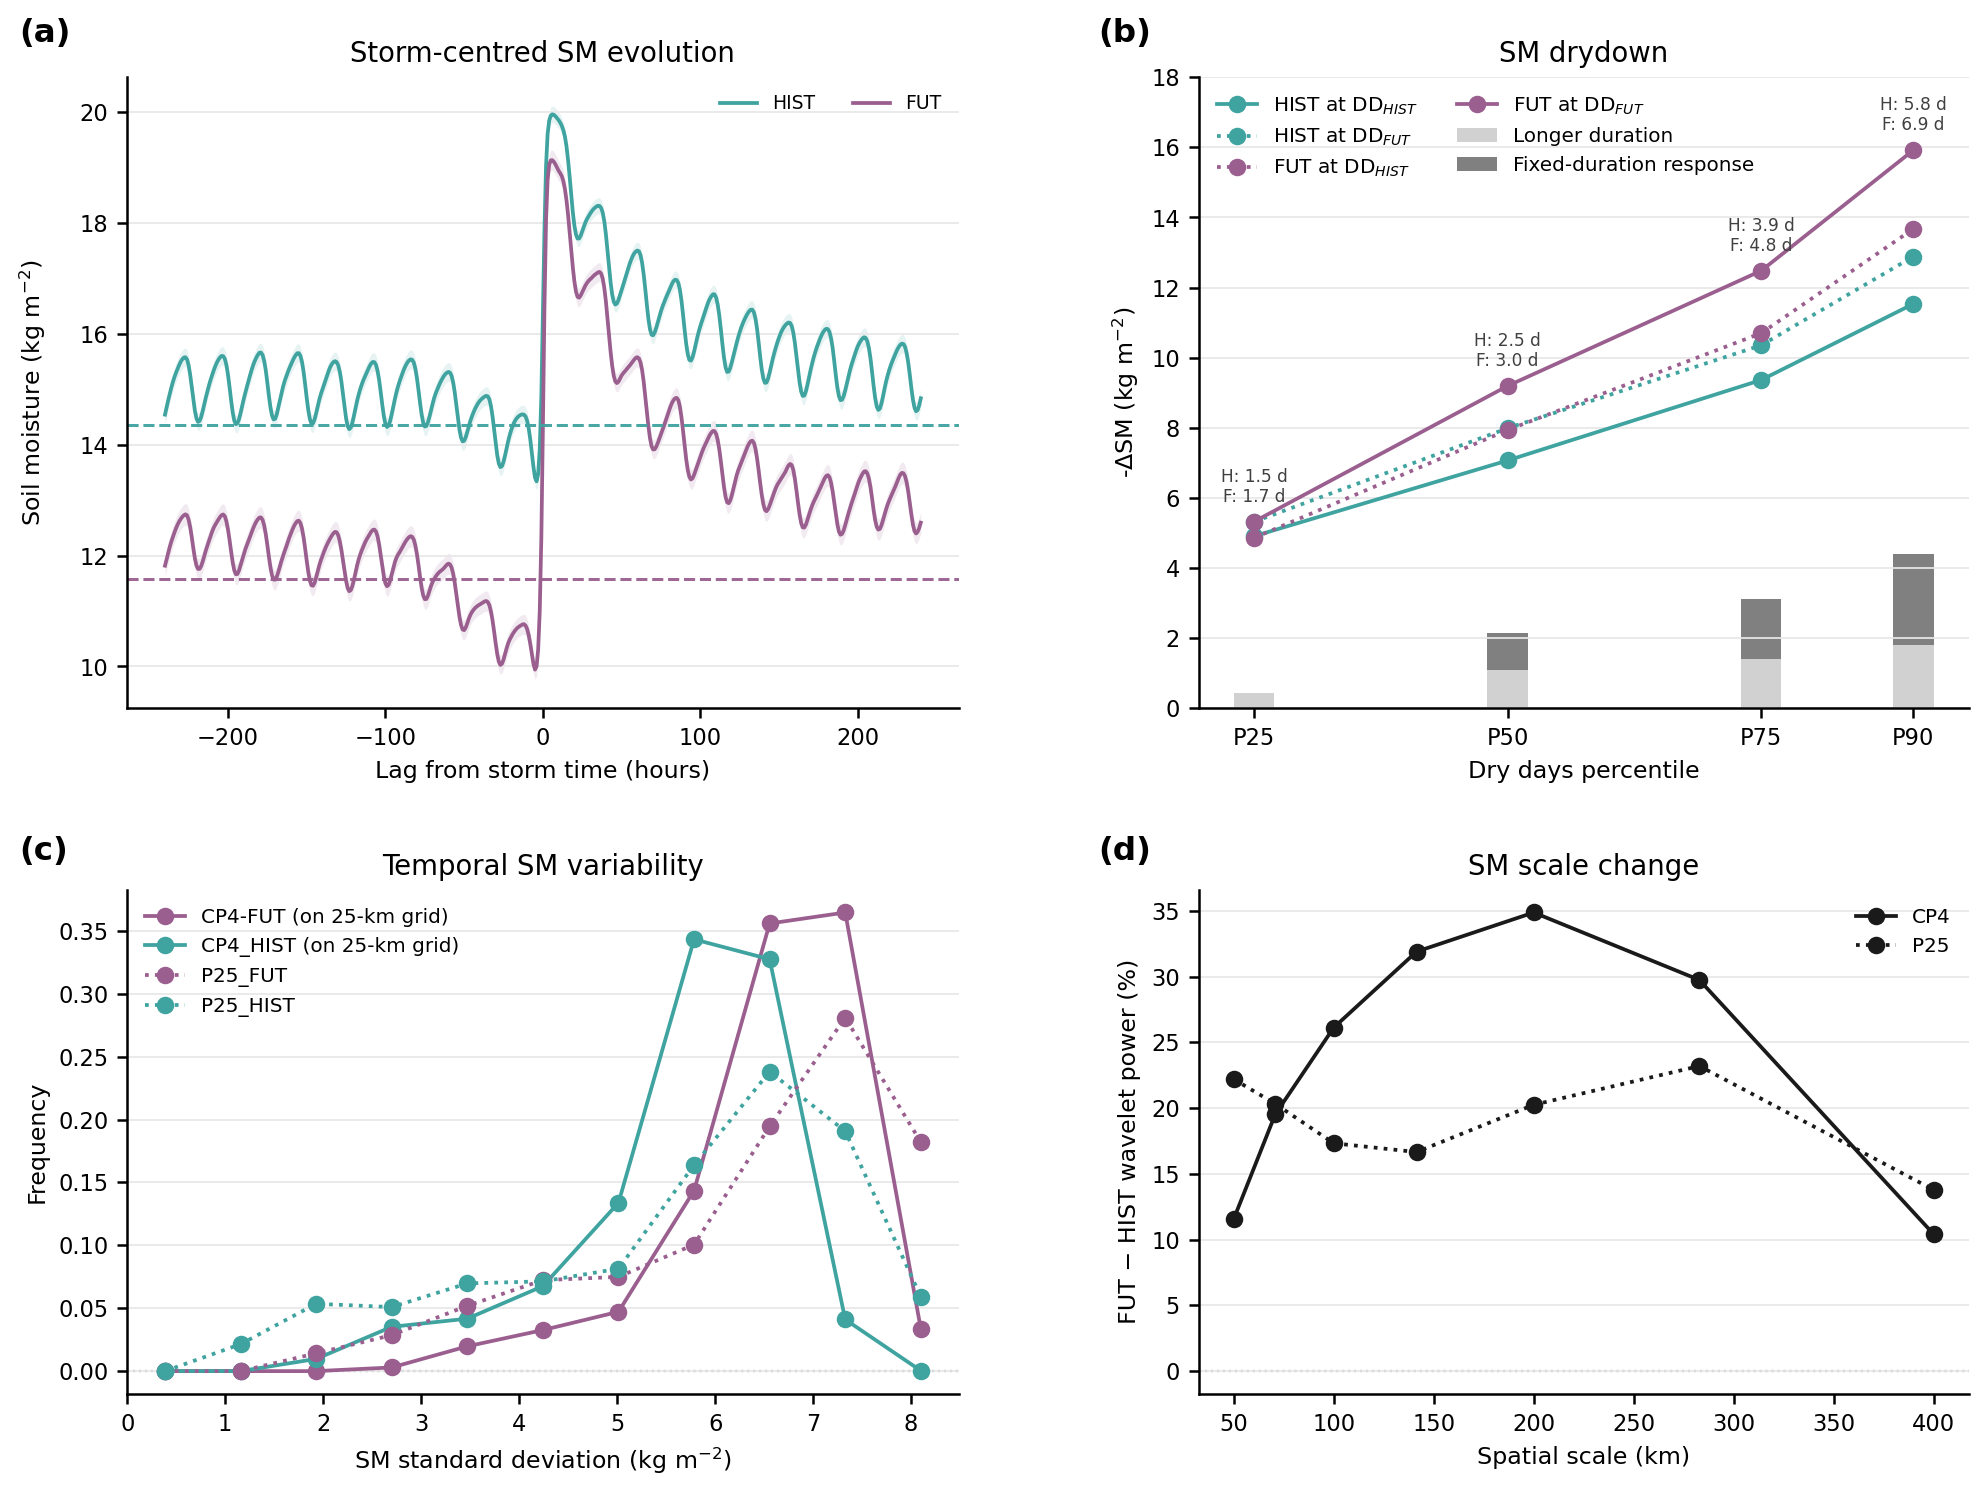

In [4]:


def style_ax(ax, zero_y=False):
    ax.spines[["top", "right"]].set_visible(False)
    ax.tick_params(direction="out", labelsize=9, width=1, length=4)
    ax.grid(axis="y", color="0.91", lw=0.7, zorder=0)

    if zero_y:
        ax.axhline(0, color="0.55", ls=":", lw=0.9, zorder=0)


def panel_label(ax, label):
    ax.text(
        -0.13, 1.045, f"({label})",
        transform=ax.transAxes,
        ha="left", va="bottom",
        fontsize=13, fontweight="semibold",
        color="black", clip_on=False,
    )


def probability(vals, bins):
    vals = np.asarray(vals, float)
    vals = vals[np.isfinite(vals)]
    n, _ = np.histogram(vals, bins=bins)
    return n / n.sum()


# ============================================================
# FIGURE
# ============================================================

fig = plt.figure(figsize=(13.2, 9.5), dpi=180)

gs = GridSpec(
    2, 2,
    figure=fig,
    width_ratios=[1.08, 1],
    height_ratios=[1.25, 1],
    wspace=0.30,
    hspace=0.32,
)

# ============================================================
# (a) Storm-centred evolution
# ============================================================

gsa = gs[0, 0].subgridspec(1, 1, hspace=0.08)  # 3,1
axa = [fig.add_subplot(gsa[i, 0]) for i in range(1)] #3

for ax, var in zip(axa, ["SM"]): #"lsRain", "sh", 

    summ = ts_summary[ts_summary["var"] == var]

    for label in ["hist", "future"]:
        sub = summ[summ["label"] == label].sort_values("lag_hour")

        x = sub["lag_hour"].values

        y = sub["mean"].values
            
        ci = sub["ci95"].values

        ax.plot(
            x, y,
            color=COL[label],
            ls=LS[label],
            lw=1.5 ,#if label == "hist" else 2.7,
            label="HIST" if label == "hist" else "FUT",
        )

        ax.fill_between(
            x, y-ci, y+ci,
            color=COL[label],
            alpha=0.13,
            linewidth=0,
        )

    # Climatological SM reference
    if var == "SM":
        for label in ["hist", "future"]:
            ax.axhline(
                SM_CLIM[label],
                color=COL[label],
                ls="--",
                lw=1.2,
                alpha=0.95,
                # label=(
                #     "Historical climatology"
                #     if label == "hist"
                #     else "Future climatology"
                # ),
            )

    # for xx in [-12, 0, 12]:
    #     ax.axvline(xx, color="0.45", lw=0.8, ls=":")

    ax.set_ylabel(
        f"{var_info[var]['label']} ({var_info[var]['unit']})"
    )

    style_ax(ax)

    if ax is not axa[-1]:
        ax.tick_params(labelbottom=False)

axa[0].set_title("Storm-centred SM evolution")
axa[-1].set_xlabel("Lag from storm time (hours)")

# one compact legend rather than repeating it three times
axa[0].legend(frameon=False, fontsize=8, loc="upper right")

# climatology key stays with SM panel
axa[-1].legend(frameon=False, fontsize=7.5, loc="upper right", ncol=2)

panel_label(axa[0], "a")


# ============================================================
# (b) Counterfactual drydown
# ============================================================

ax = fig.add_subplot(gs[0, 1])

p = decomp["percentile"].values

# HIST drying behaviour
ax.plot(
    p, decomp["D_hist_at_Thist"],
    marker="o",
    color=HIST_COL,
    ls="-",
    lw=1.5,
    label=r"HIST at DD$_{HIST}$",
)

ax.plot(
    p, decomp["D_hist_at_Tfuture"],
    marker="o",
    color=HIST_COL,
    ls=":",
    lw=1.5,
    label=r"HIST at DD$_{FUT}$",
)

# FUT drying behaviour
ax.plot(
    p, decomp["D_future_at_Thist"],
    marker="o",
    color=FUT_COL,
    ls=":",
    lw=1.5,
    label=r"FUT at DD$_{HIST}$",
)

ax.plot(
    p, decomp["D_future_at_Tfuture"],
    marker="o",
    color=FUT_COL,
    ls="-",
    lw=1.5,
    label=r"FUT at DD$_{FUT}$",
)

ax.set_xticks(p)
ax.set_xticklabels([f"P{int(x)}" for x in p])

ax.set(
    xlabel="Dry days percentile",
    ylabel=r"-$\Delta$SM (kg m$^{-2}$)",
    title="SM drydown",
)

# Give annotations some headroom
ax.set_ylim(0, 18)

# Actual HIST/FUT drying duration at each percentile,
# positioned just above FUT at DD_FUT
for _, row in decomp.iterrows():
    x = row["percentile"]
    y = row["D_future_at_Tfuture"] + 0.45

    ax.text(
        x, y,
        f"H: {row['T_hist']:.1f} d\nF: {row['T_future']:.1f} d",
        ha="center",
        va="bottom",
        fontsize=6.8,
        linespacing=1.15,
        color="0.25",
    )


barw = 4.0

ax.bar(
    p,
    decomp["duration_contribution"],
    width=barw,
    color="0.82",
    edgecolor="none",
    zorder=1,
    label="Longer duration",
)

ax.bar(
    p,
    decomp["response_contribution"],
    bottom=decomp["duration_contribution"],
    width=barw,
    color="0.50",
    edgecolor="none",
    zorder=1,
    label="Fixed-duration response",
)

# ============================================================
# Percentage contribution: duration vs drying response
# Main-text estimate from P25, P50, P75
# ============================================================

main = decomp[decomp["percentile"].isin([25, 50, 75])].copy()

duration_pct = (
    100 * main["duration_contribution"].mean()
        / main["total_difference"].mean()
)

response_pct = (
    100 * main["response_contribution"].mean()
        / main["total_difference"].mean()
)

print(f"Longer drying duration:       {duration_pct:.1f}%")
print(f"Stronger fixed-time drying:   {response_pct:.1f}%")
print(f"Check:                        {duration_pct + response_pct:.1f}%")


ax.legend(frameon=False, fontsize=8, ncol=2)
style_ax(ax)
panel_label(ax, "b")

print("\nContribution by percentile:")

for _, r in main.iterrows():
    dur = 100 * r["duration_contribution"] / r["total_difference"]
    resp = 100 * r["response_contribution"] / r["total_difference"]

    print(
        f"P{int(r['percentile'])}: "
        f"duration {dur:.1f}%, "
        f"response {resp:.1f}%"
    )


# ============================================================
# (c) Temporal SM variability
# ============================================================

ax = fig.add_subplot(gs[1, 0])

smstd = std["SM_std_mean_years"]

cp_h = smstd.sel(experiment="CP4hist").values.ravel()
cp_f = smstd.sel(experiment="CP4fut").values.ravel()
p_h  = smstd.sel(experiment="P25hist").values.ravel()
p_f  = smstd.sel(experiment="P25fut").values.ravel()

allv = np.concatenate([cp_h, cp_f, p_h, p_f])
allv = allv[np.isfinite(allv)]

bins = np.linspace(
    0,
    np.nanpercentile(allv, 99.5),
    12
)

centres = 0.5 * (bins[:-1] + bins[1:])

ax.plot(
    centres,
    probability(cp_f, bins), #- probability(cp_h, bins),
    marker="o",
    color=FUT_COL,
    lw=1.5,
    label="CP4-FUT (on 25-km grid)",
)

ax.plot(
    centres,
    probability(cp_h, bins),
    marker="o",
    color=HIST_COL,
    lw=1.5,
    label="CP4_HIST (on 25-km grid)",
)

ax.plot(
    centres,
    probability(p_f, bins),
    marker="o",
    color=FUT_COL,
    ls=":",
    lw=1.5,
    label="P25_FUT",
)

ax.plot(
    centres,
    probability(p_h, bins),
    marker="o",
    color=HIST_COL,
    ls=":",
    lw=1.5,
    label="P25_HIST",
)

ax.set(
    xlabel=r"SM standard deviation (kg m$^{-2}$)",
    ylabel="Frequency",
    title="Temporal SM variability",
)

ax.legend(frameon=False, fontsize=8)
style_ax(ax, zero_y=True)
panel_label(ax, "c")


# ============================================================
# (d) Scale-dependent spatial power
# ============================================================

ax = fig.add_subplot(gs[1, 1])

power = wav["power_mean_years"]
scales = wav["scale"].values

for model, ls, label in [
    ("CP4", "-", "CP4"),
    ("P25", ":", "P25"),
]:

    hist = power.sel(experiment=f"{model}hist").values
    fut = power.sel(experiment=f"{model}fut").values

    change = 100 * (fut-hist) / hist

    ax.plot(
        scales,
        change,
        marker="o",
        color="0.10",
        ls=ls,
        lw=1.5 if model == "CP4" else 1.5,
        label=label,
    )

ax.set(
    xlabel="Spatial scale (km)",
    ylabel="FUT − HIST wavelet power (%)",
    title="SM scale change",
)

ax.legend(frameon=False, fontsize=8)
style_ax(ax, zero_y=True)
panel_label(ax, "d")


# ============================================================
# Finish
# ============================================================

fig.align_ylabels()
plt.tight_layout(w_pad=1.7, h_pad=2.0)

# optional:
fig.savefig(
    '/home/users/cornkle/pythonWorkspace/proj_CEH/JASMIN/CP4_sm_paper/figures/fig3_timeseries_drydown.jpg',
    dpi=300,
    bbox_inches="tight"
)

plt.show()